In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [28]:
df = pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA

In [29]:
df.shape

(1338, 7)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [31]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [32]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [34]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


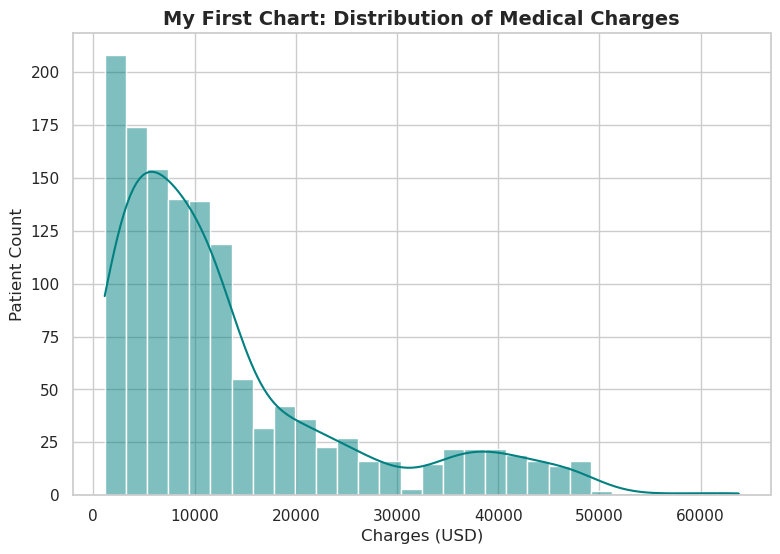

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the visual style so it looks clean
sns.set_theme(style="whitegrid")

# 2. Create the canvas size
plt.figure(figsize=(9, 6))

# 3. Draw the histogram of your target column
sns.histplot(df['charges'], kde=True, color='teal', bins=30)
# 4. Add clear labels
plt.title('My First Chart: Distribution of Medical Charges', fontsize=14, fontweight='bold')
plt.xlabel('Charges (USD)', fontsize=12)
plt.ylabel('Patient Count', fontsize=12)

# 5. Display it
plt.show()

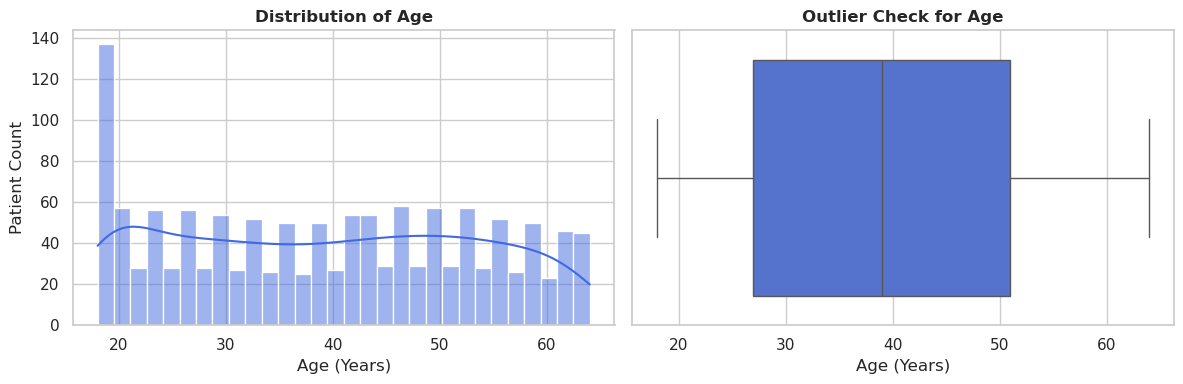

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

# --- Chart 1: The Histogram (How ages are spread) ---
plt.subplot(1, 2, 1)
sns.histplot(df['age'], kde=True, color='royalblue', bins=30)
plt.title('Distribution of Age', fontsize=12, fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Patient Count')

# --- Chart 2: The Box Plot (Hunting for age outliers) ---
plt.subplot(1, 2, 2)
sns.boxplot(x=df['age'], color='royalblue')
plt.title('Outlier Check for Age', fontsize=12, fontweight='bold')
plt.xlabel('Age (Years)')

plt.tight_layout()
plt.show()

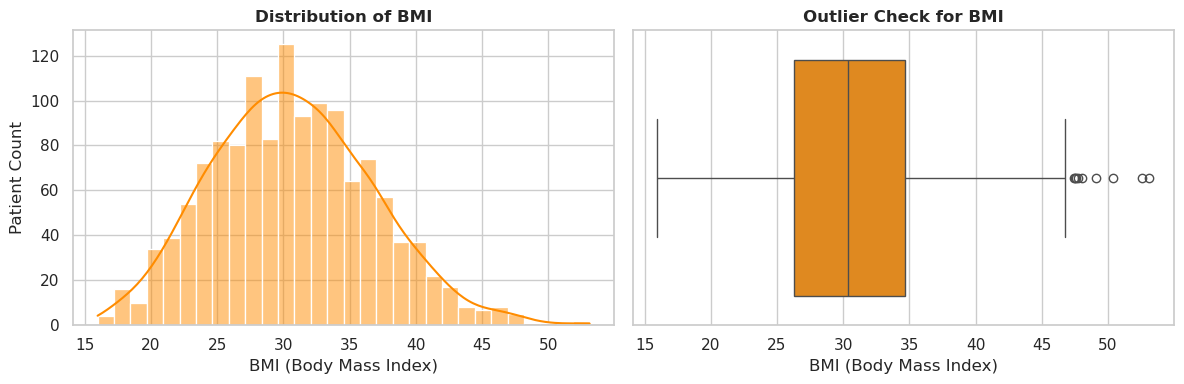

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

# --- Chart 1: The Histogram (How BMI is spread) ---
plt.subplot(1, 2, 1)
sns.histplot(df['bmi'], kde=True, color='darkorange', bins=30)
plt.title('Distribution of BMI', fontsize=12, fontweight='bold')
plt.xlabel('BMI (Body Mass Index)')
plt.ylabel('Patient Count')

# --- Chart 2: The Box Plot (Hunting for BMI outliers) ---
plt.subplot(1, 2, 2)
sns.boxplot(x=df['bmi'], color='darkorange')
plt.title('Outlier Check for BMI', fontsize=12, fontweight='bold')
plt.xlabel('BMI (Body Mass Index)')

plt.tight_layout()
plt.show()

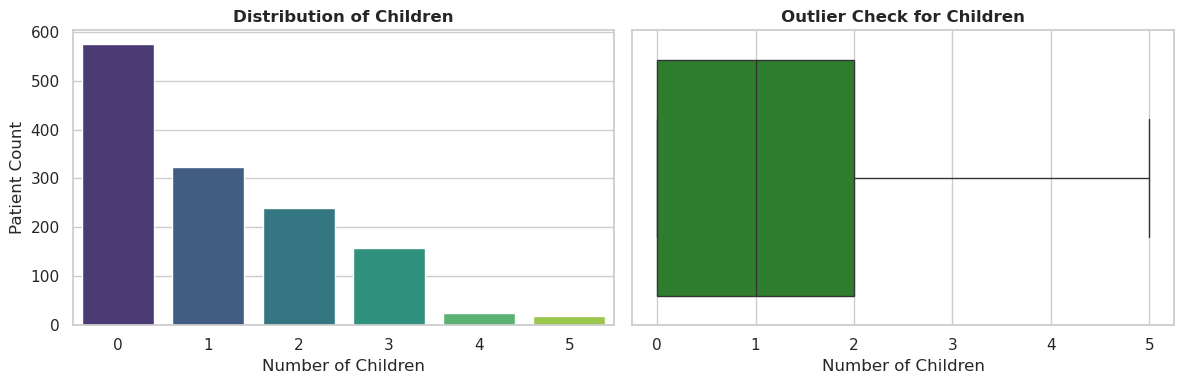

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

# --- Chart 1: Count Plot (How many patients have 0, 1, 2, etc. kids) ---
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='children', palette='viridis')
plt.title('Distribution of Children', fontsize=12, fontweight='bold')
plt.xlabel('Number of Children')
plt.ylabel('Patient Count')

# --- Chart 2: Box Plot (Checking for weird values) ---
plt.subplot(1, 2, 2)
sns.boxplot(x=df['children'], color='forestgreen')
plt.title('Outlier Check for Children', fontsize=12, fontweight='bold')
plt.xlabel('Number of Children')

plt.tight_layout()
plt.show()

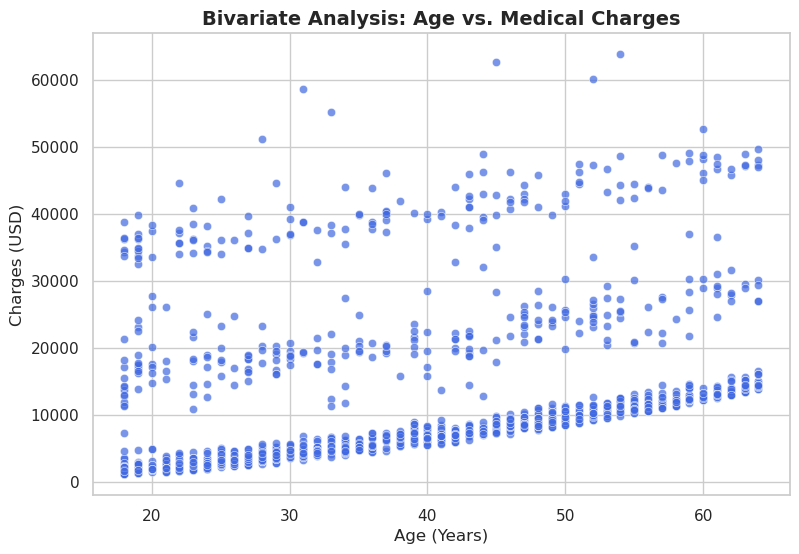

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the canvas size
plt.figure(figsize=(9, 6))

# 2. Create a scatter plot comparing Age to Charges
sns.scatterplot(data=df, x='age', y='charges', alpha=0.7, color='royalblue')

# 3. Add clear titles and labels
plt.title('Bivariate Analysis: Age vs. Medical Charges', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Charges (USD)', fontsize=12)

# 4. Display the plot
plt.show()

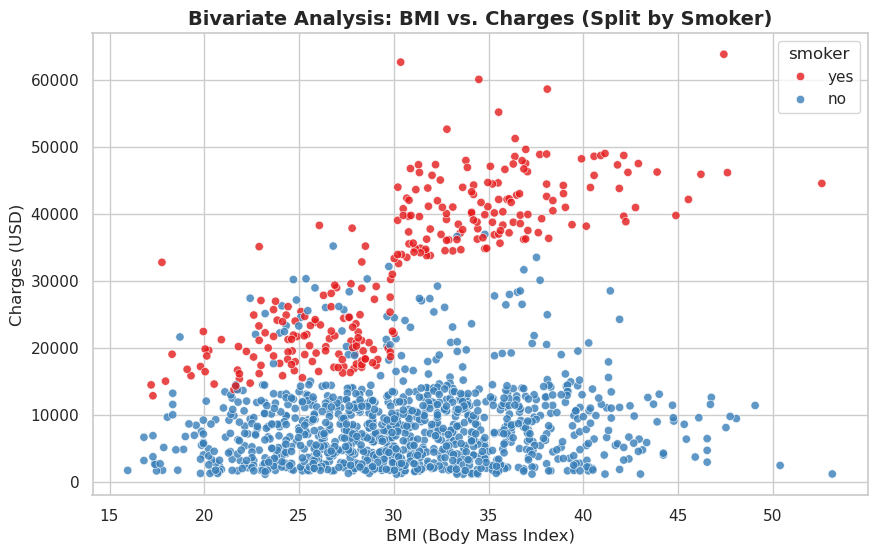

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the canvas size
plt.figure(figsize=(10, 6))

# 2. Create a scatter plot with bmi vs charges, split/colored by smoker
sns.scatterplot(
    data=df, 
    x='bmi', 
    y='charges', 
    hue='smoker',       # This splits the dots into colors based on smoker status!
    palette='Set1',     # Chooses distinct colors
    alpha=0.8
)

# 3. Add titles and labels
plt.title('Bivariate Analysis: BMI vs. Charges (Split by Smoker)', fontsize=14, fontweight='bold')
plt.xlabel('BMI (Body Mass Index)', fontsize=12)
plt.ylabel('Charges (USD)', fontsize=12)

plt.show()

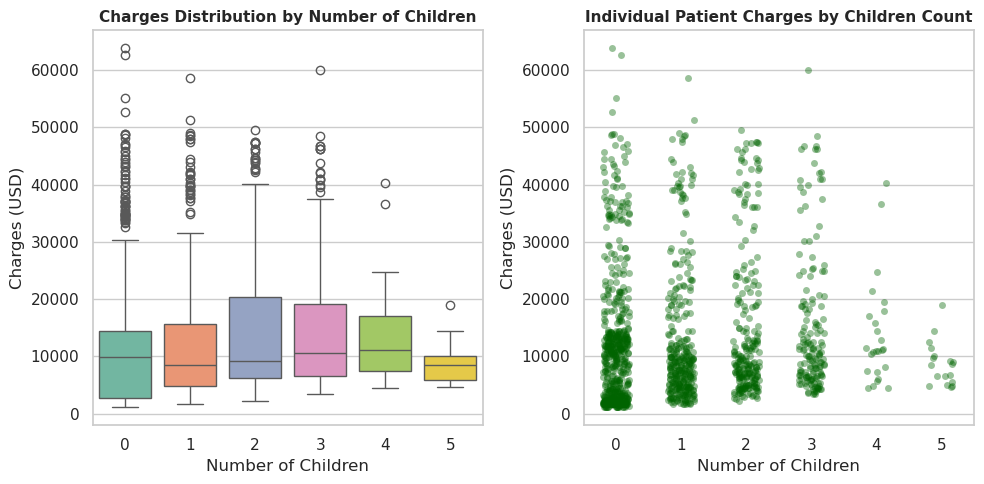

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# --- Chart 1: Box plot to see median charges per child count ---
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='children', y='charges', palette='Set2')
plt.title('Charges Distribution by Number of Children', fontsize=11, fontweight='bold')
plt.xlabel('Number of Children')
plt.ylabel('Charges (USD)')

# --- Chart 2: Strip plot (Jittered dots to see density) ---
plt.subplot(1, 2, 2)
sns.stripplot(data=df, x='children', y='charges', color='darkgreen', alpha=0.4, jitter=0.2)
plt.title('Individual Patient Charges by Children Count', fontsize=11, fontweight='bold')
plt.xlabel('Number of Children')
plt.ylabel('Charges (USD)')

plt.tight_layout()
plt.show()

In [55]:
# Convert binary text features into 0s and 1s
df['smoker_encoded'] = df['smoker'].map({'no': 0, 'yes': 1})
df['sex_encoded'] = df['sex'].map({'female': 0, 'male': 1})

In [56]:
df

,age,sex,bmi,children,smoker,region,charges,smoker_encoded,sex_encoded
0,19,female,27.900,0,yes,southwest,16884.92400,1,0
1,18,male,33.770,1,no,southeast,1725.55230,0,1
2,28,male,33.000,3,no,southeast,4449.46200,0,1
3,33,male,22.705,0,no,northwest,21984.47061,0,1
4,32,male,28.880,0,no,northwest,3866.85520,0,1
...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,1
1334,18,female,31.920,0,no,northeast,2205.98080,0,0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0


In [57]:
# One-hot encode multi-class categorical features
df_encoded = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)

# View the converted structure

df_encoded.head()

,age,sex,bmi,children,smoker,charges,smoker_encoded,sex_encoded,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,16884.92400,1,0,0,0,1
1,18,male,33.770,1,no,1725.55230,0,1,0,1,0
2,28,male,33.000,3,no,4449.46200,0,1,0,1,0
3,33,male,22.705,0,no,21984.47061,0,1,1,0,0
4,32,male,28.880,0,no,3866.85520,0,1,1,0,0


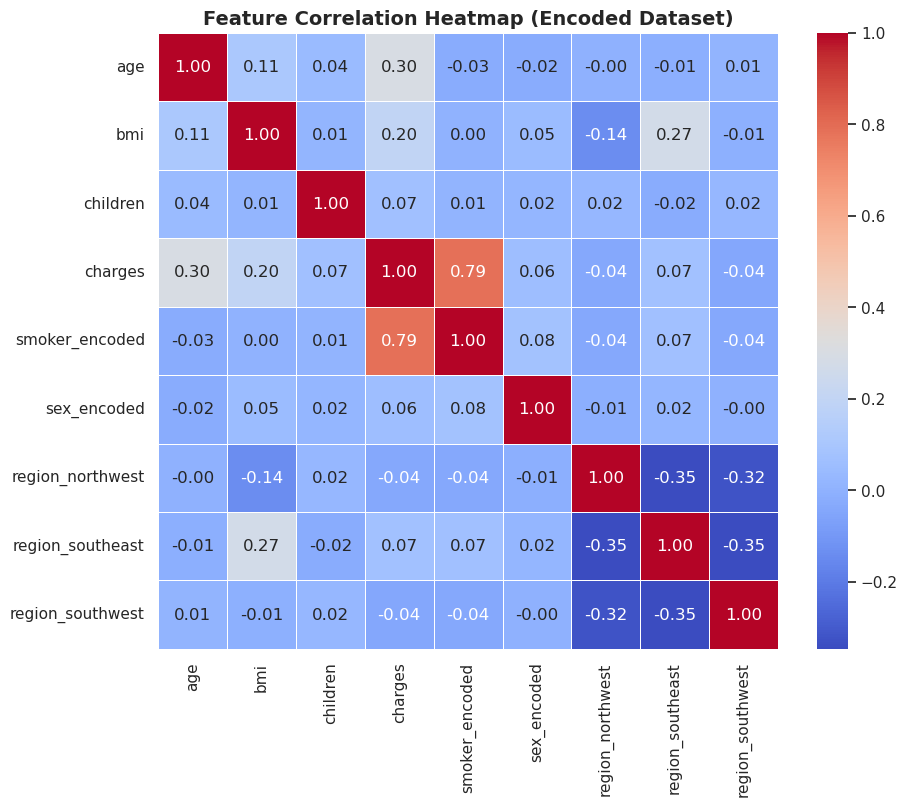

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compute the correlation matrix using only numerical and encoded columns
corr_matrix = df_encoded.select_dtypes(include=['number']).corr()

# 2. Set the canvas size
plt.figure(figsize=(10, 8))

# 3. Draw the heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,       # Display the correlation numbers inside each box
    cmap='coolwarm',  # Red = positive correlation, Blue = negative correlation
    fmt='.2f',        # Round to 2 decimal places
    linewidths=0.5,   # Add thin grid lines between cells
    cbar=True         # Show the color scale bar on the side
)

# 4. Add title and display
plt.title('Feature Correlation Heatmap (Encoded Dataset)', fontsize=14, fontweight='bold')
plt.show()

In [59]:
from sklearn.preprocessing import StandardScaler

# 1. Initialize the scaler
scaler = StandardScaler()

# 2. Select the continuous/numerical columns that need scaling
num_cols = ['age', 'bmi', 'children']

# 3. Fit and transform those columns in our encoded dataframe
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

# 4. View the scaled data preview
df_encoded[num_cols].head()

,age,bmi,children
0,-1.438764,-0.453320,-0.908614
1,-1.509965,0.509621,-0.078767
2,-0.797954,0.383307,1.580926
3,-0.441948,-1.305531,-0.908614
4,-0.513149,-0.292556,-0.908614


In [61]:
from sklearn.model_selection import train_test_split

# 1. Define Features (X) by dropping 'charges', the old text columns ('sex', 'smoker'), and keeping our encoded versions
X = df_encoded.drop(columns=['charges', 'sex', 'smoker'])

# 2. Define Target (y)
y = df_encoded['charges']

# 3. Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Verify the shapes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training features shape: (1070, 8)
Testing features shape: (268, 8)


In [62]:
from sklearn.linear_model import LinearRegression

# 1. Initialize the Linear Regression model
model = LinearRegression()

# 2. Train (fit) the model using your training data
model.fit(X_train, y_train)

print("Model training complete! Your model has learned the patterns.")

Model training complete! Your model has learned the patterns.


In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Generate predictions using the test set
y_pred = model.predict(X_test)

# 2. Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# 3. Print out the results in real USD terms
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Absolute Error (MAE): $4181.19
Root Mean Squared Error (RMSE): $5796.28
R-squared (R2) Score: 0.7836


In [65]:
import joblib

# 1. Save the trained model
joblib.dump(model, 'medical_cost_model.pkl')

# 2. Save the fitted scaler so new data gets scaled the exact same way
joblib.dump(scaler, 'scaler.pkl')

print("Model and scaler saved successfully as .pkl files!")

Model and scaler saved successfully as .pkl files!
